In [36]:
# Instala bibliotecas necessárias
!pip install datasets emoji seaborn matplotlib
import re
import emoji
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix
import joblib

In [37]:
# Configuração visual dos gráficos
sns.set_theme(style="dark")
plt.rcParams['figure.figsize'] = (8, 4)

In [38]:
#from google.colab import drive
#drive.mount('/content/drive')

#path = '/content/drive/MyDrive/PLN_Projeto'

In [39]:
# fixando um random state para garantir a reprodutibilidade
RANDOM_STATE = 42

# 1. Limpeza e Engenharia do Corpus

In [97]:
# Baixa o CSV diretamente do repositório oficial da B2W
url = "https://raw.githubusercontent.com/americanas-tech/b2w-reviews01/main/B2W-Reviews01.csv"

df_raw = pd.read_csv(url, sep=",", low_memory=False)

print(f"Quantificade Inicial de Registros e colunas: {df_raw.shape}")

display(df_raw.head())

print(f'\nColunas da base:')
display(df_raw.info())

Quantificade Inicial de Registros e colunas: (132373, 14)


,submission_date,reviewer_id,product_id,product_name,product_brand,site_category_lv1,site_category_lv2,review_title,overall_rating,recommend_to_a_friend,review_text,reviewer_birth_year,reviewer_gender,reviewer_state
0,2018-01-01 00:11:28,d0fb1ca69422530334178f5c8624aa7a99da47907c44de...,132532965,Notebook Asus Vivobook Max X541NA-GO472T Intel...,NaN,Informática,Notebook,Bom,4,Yes,Estou contente com a compra entrega rápida o ú...,1958.0,F,RJ
1,2018-01-01 00:13:48,014d6dc5a10aed1ff1e6f349fb2b059a2d3de511c7538a...,22562178,Copo Acrílico Com Canudo 500ml Rocie,NaN,Utilidades Domésticas,"Copos, Taças e Canecas","Preço imbatível, ótima qualidade",4,Yes,"Por apenas R$1994.20,eu consegui comprar esse ...",1996.0,M,SC
2,2018-01-01 00:26:02,44f2c8edd93471926fff601274b8b2b5c4824e386ae4f2...,113022329,Panela de Pressão Elétrica Philips Walita Dail...,philips walita,Eletroportáteis,Panela Elétrica,ATENDE TODAS AS EXPECTATIVA.,4,Yes,SUPERA EM AGILIDADE E PRATICIDADE OUTRAS PANEL...,1984.0,M,SP
3,2018-01-01 00:35:54,ce741665c1764ab2d77539e18d0e4f66dde6213c9f0863...,113851581,Betoneira Columbus - Roma Brinquedos,roma jensen,Brinquedos,Veículos de Brinquedo,presente mais que desejado,4,Yes,MEU FILHO AMOU! PARECE DE VERDADE COM TANTOS D...,1985.0,F,SP
4,2018-01-01 01:00:28,7d7b6b18dda804a897359276cef0ca252f9932bf4b5c8e...,131788803,"Smart TV LED 43"" LG 43UJ6525 Ultra HD 4K com C...",lg,TV e Home Theater,TV,"Sem duvidas, excelente",5,Yes,"A entrega foi no prazo, as americanas estão de...",1994.0,M,MG



Colunas da base:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 132373 entries, 0 to 132372
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   submission_date        132373 non-null  object 
 1   reviewer_id            132373 non-null  object 
 2   product_id             132373 non-null  object 
 3   product_name           132289 non-null  object 
 4   product_brand          40982 non-null   object 
 5   site_category_lv1      132367 non-null  object 
 6   site_category_lv2      128360 non-null  object 
 7   review_title           132071 non-null  object 
 8   overall_rating         132373 non-null  int64  
 9   recommend_to_a_friend  132355 non-null  object 
 10  review_text            129098 non-null  object 
 11  reviewer_birth_year    126389 non-null  float64
 12  reviewer_gender        128237 non-null  object 
 13  reviewer_state         128382 non-null  object 
dtypes: float64(1), int

None

In [96]:
# Seleciona as duas colunas essenciais: texto da avaliação e nota dada pelo cliente
'''df = df_raw[['review_title', 'review_text', 'overall_rating']].copy()

print(f'Quantidade de linhas com valores nulos:')
display(df.isna().sum())

# convertendo os tipos de colunas e revomendo os valores NaN
df.dropna(subset=['review_text'], inplace=True)
df['review_text'] = df['review_text'].astype(str)
df['overall_rating'] = pd.to_numeric(df['overall_rating'], errors='coerce')
df.dropna(subset=['overall_rating'], inplace=True)

print(f'\nQuantidade de linhas com valores nulos após tratamento:')
display(df.isna().sum())

print(f"Quantificade de Registros e colunas: {df.shape}")'''

Quantidade de linhas com valores nulos:


,0
review_title,302
review_text,3275
overall_rating,0



Quantidade de linhas com valores nulos após tratamento:


,0
review_title,230
review_text,0
overall_rating,0


Quantificade de Registros e colunas: (129098, 3)


In [98]:
df = df_raw[['review_title', 'review_text', 'overall_rating']].copy()

print('Quantidade de linhas com valores nulos:')
display(df.isna().sum())

# Convertendo os tipos de colunas e removendo os valores NaN
df.dropna(subset=['review_text'], inplace=True)
df['overall_rating'] = pd.to_numeric(df['overall_rating'], errors='coerce')
df.dropna(subset=['overall_rating'], inplace=True)

# Preenchendo títulos nulos e juntando com o texto da avaliação
df['review_title'] = df['review_title'].fillna('').astype(str).str.strip()
df['review_text'] = df['review_text'].astype(str).str.strip()

df['review_text'] = np.where(
    df['review_title'] != '',
    df['review_title'] + '. ' + df['review_text'],
    df['review_text']
)

df.drop(columns=['review_title'], inplace=True)

print('\nQuantidade de linhas com valores nulos após tratamento:')
display(df.isna().sum())

print(f"Quantidade de Registros e colunas: {df.shape}")

Quantidade de linhas com valores nulos:


,0
review_title,302
review_text,3275
overall_rating,0



Quantidade de linhas com valores nulos após tratamento:


,0
review_text,0
overall_rating,0


Quantidade de Registros e colunas: (129098, 2)


Distribuição das Notas:
Nota 1 estrelas: 25,646 (19.87%)
Nota 2 estrelas: 8,126 (6.29%)
Nota 3 estrelas: 16,010 (12.40%)
Nota 4 estrelas: 31,987 (24.78%)
Nota 5 estrelas: 47,329 (36.66%)


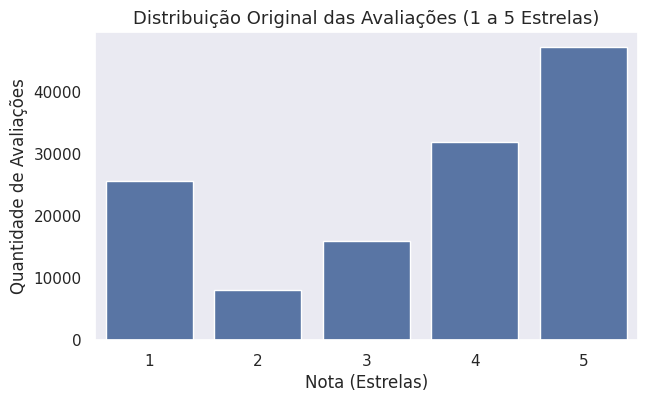

In [99]:
# Contagem e percentual de cada nota (1 a 5 estrelas)
contagem_notas = df['overall_rating'].value_counts().sort_index()
percentuais = (contagem_notas / len(df)) * 100

print("Distribuição das Notas:")
for nota, count in contagem_notas.items():
    print(f"Nota {int(nota)} estrelas: {count:,} ({percentuais[nota]:.2f}%)")

# Gráfico de barras para colocar no relatório
plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df, x='overall_rating')
plt.title("Distribuição Original das Avaliações (1 a 5 Estrelas)", fontsize=13)
plt.xlabel("Nota (Estrelas)")
plt.ylabel("Quantidade de Avaliações")
#plt.savefig(f"{path}/Graficos/distribuicao_original_estrelas.png", dpi=300, bbox_inches='tight')
plt.show()

## 1.1 Mapeamento de Sentimentos (3 classes e 2 classes)

In [100]:
def rotular_sentimentos(nota):
  if nota in [1, 2]:
    return "Negativo"

  elif nota == 3:
    return "Neutro"

  elif nota in [4, 5]:
    return "Positivo"

  return np.nan

# def rotular_sentimentos_2_classes(nota):
#   if nota in [1, 2]:
#     return "Negativo"

#   elif nota in [4, 5]:
#     return "Positivo"

#   return np.nan

Distribuição Desbalanceada das Classes:


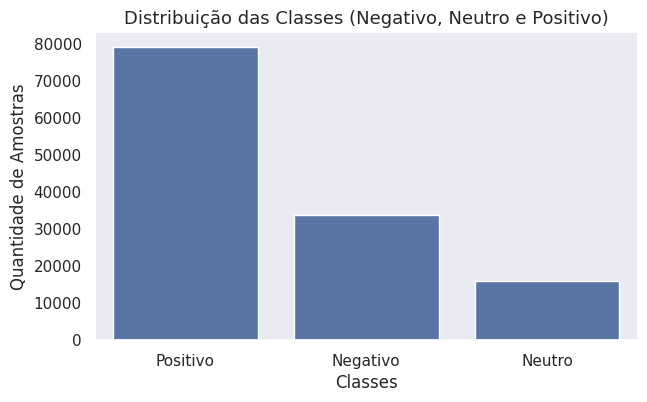

In [101]:
df['sentimento'] = df['overall_rating'].apply(rotular_sentimentos)

print('Distribuição Desbalanceada das Classes:')
df['sentimento'].value_counts()

# Gráfico de barras para colocar no relatório
plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df, x='sentimento')
plt.title("Distribuição das Classes (Negativo, Neutro e Positivo)", fontsize=13)
plt.xlabel("Classes")
plt.ylabel("Quantidade de Amostras")
#plt.savefig(f"{path}/Graficos/distribuicao_classes_desbalanceadas.png", dpi=300, bbox_inches='tight')
plt.show()

## 1.2 Limpeza e Saneamento Textual

In [102]:
def limpar_texto(texto):

  if not isinstance(texto, str):
        return ""

  # Remove tags HTML (ex: <br />, <p>)
  texto = re.sub(r'<.*?>', ' ', texto)

  # Remove URLs/links
  texto = re.sub(r'http\S+|www\S+|https\S+', '', texto, flags=re.MULTILINE)

  # Converte emojis em texto amigável ou preserva (demojize)
  # Ex: transforma '😍' em ':smiling_face_with_heart-eyes:' para o modelo entender o sentimento
  texto = emoji.demojize(texto, language='pt')

  # Normaliza espaços múltiplos e quebras de linha
  texto = re.sub(r'\s+', ' ', texto).strip()

  return texto

print("Aplicando limpeza nos textos...")
df['texto_limpo'] = df['review_text'].apply(limpar_texto)

# Remove textos que ficaram muito curtos após a limpeza (menos de 3 caracteres)
df = df[df['texto_limpo'].str.len() >= 3].copy()

print("Limpeza concluída!")
df.head()

Aplicando limpeza nos textos...
Limpeza concluída!


,review_text,overall_rating,sentimento,texto_limpo
0,Bom. Estou contente com a compra entrega rápid...,4,Positivo,Bom. Estou contente com a compra entrega rápid...
1,"Preço imbatível, ótima qualidade. Por apenas R...",4,Positivo,"Preço imbatível, ótima qualidade. Por apenas R..."
2,ATENDE TODAS AS EXPECTATIVA.. SUPERA EM AGILID...,4,Positivo,ATENDE TODAS AS EXPECTATIVA.. SUPERA EM AGILID...
3,presente mais que desejado. MEU FILHO AMOU! PA...,4,Positivo,presente mais que desejado. MEU FILHO AMOU! PA...
4,"Sem duvidas, excelente. A entrega foi no prazo...",5,Positivo,"Sem duvidas, excelente. A entrega foi no prazo..."


## 1.3 Balanceamento das Classes

In [103]:
# Pegando o menor numero de amostras dentre as classes
n_por_classe = df['sentimento'].value_counts().min()

print(f'O menor número de amostras por classe será: {n_por_classe}')

# selecionando aleatoriamente 16010 amostras por classe
df_balanceado = (
    df.groupby('sentimento', group_keys=False)
      .apply(lambda x: x.sample(n=n_por_classe, random_state=RANDOM_STATE))
      .reset_index(drop=True)
)

print("\nDataset balanceado final:")
print(df_balanceado['sentimento'].value_counts())

df_balanceado.head(3)

O menor número de amostras por classe será: 16010

Dataset balanceado final:
sentimento
Negativo    16010
Neutro      16010
Positivo    16010
Name: count, dtype: int64


/tmp/ipykernel_517/3092143746.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=n_por_classe, random_state=RANDOM_STATE))


,review_text,overall_rating,sentimento,texto_limpo
0,Vazamento no primeiro uso. Comprei a caixa est...,1,Negativo,Vazamento no primeiro uso. Comprei a caixa est...
1,Cadê o produto ???. Não recebi depois de seman...,1,Negativo,Cadê o produto ???. Não recebi depois de seman...
2,Horrível. Não posso dizer sobre o produto pois...,2,Negativo,Horrível. Não posso dizer sobre o produto pois...


## 1.4 Mapeamento Númerico das classes

In [104]:
# Mapeando numericamente as classes
label_map ={
    'Negativo': 0,
    'Neutro': 1,
    'Positivo': 2
}

df_balanceado['label_sentimento'] = df_balanceado['sentimento'].map(label_map)

# tirando colunas desnecessarias
df_balanceado.drop(columns = ['review_text', 'overall_rating', 'sentimento'], inplace=True)
df_balanceado.head(3)

,texto_limpo,label_sentimento
0,Vazamento no primeiro uso. Comprei a caixa est...,0
1,Cadê o produto ???. Não recebi depois de seman...,0
2,Horrível. Não posso dizer sobre o produto pois...,0


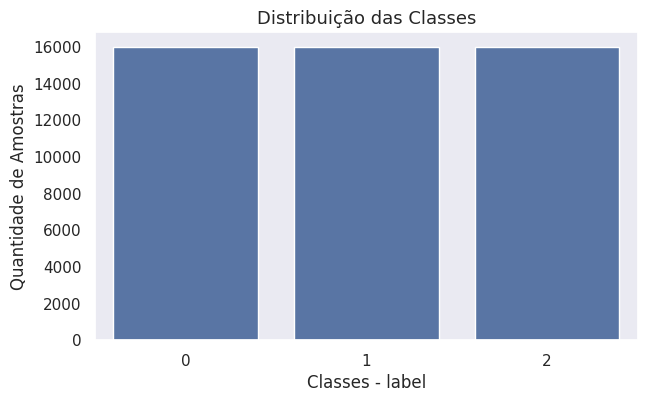

In [105]:
# Gráfico de barras para colocar no relatório
plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df_balanceado, x='label_sentimento')
plt.title("Distribuição das Classes", fontsize=13)
plt.xlabel("Classes - label")
plt.ylabel("Quantidade de Amostras")
#plt.savefig(f"{path}/Graficos/distribuicao_classes_balanceadas.png", dpi=300, bbox_inches='tight')
plt.show()

## 1.5 Divisão Estratificada (Treino 70%, Validação 15%, Teste 15%)

In [106]:
# 1. Separa 70% para treino e 30% temporário
df_train, df_temp = train_test_split(
    df_balanceado,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=df_balanceado['label_sentimento']
)
# 2. Divide os 30% em Validação (15%) e Teste (15%)
df_val, df_test = train_test_split(
    df_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=df_temp['label_sentimento']
)
print(f"Total Treino:     {len(df_train)} ({len(df_train)/len(df_balanceado):.1%})")
print(f"Total Validação:  {len(df_val)} ({len(df_val)/len(df_balanceado):.1%})")
print(f"Total Teste:      {len(df_test)} ({len(df_test)/len(df_balanceado):.1%})")

Total Treino:     33621 (70.0%)
Total Validação:  7204 (15.0%)
Total Teste:      7205 (15.0%)


In [107]:
X_train, y_train = df_train['texto_limpo'], df_train['label_sentimento'].astype(int)
X_val, y_val = df_val['texto_limpo'], df_val['label_sentimento'].astype(int)
X_test, y_test = df_test['texto_limpo'], df_test['label_sentimento'].astype(int)

print(f"Treino: {len(X_train)} | Validação: {len(X_val)} | Teste: {len(X_test)}")

Treino: 33621 | Validação: 7204 | Teste: 7205


# 2. Linha de Base Clássica com ML Tradicional

In [108]:
def desempenho_modelo(y_test, pred_y, model = 'Modelo'):
  acc_lr = accuracy_score(y_test, pred_y)
  f1_lr = f1_score(y_test, pred_y, average='macro')
  precision_lr = precision_score(y_test, pred_y, average='macro')
  recall_lr = recall_score(y_test, pred_y, average='macro')

  # guardar em um arquivo csv
  resultados = pd.DataFrame({
    'Modelo': [model],
    'Accuracy': [acc_lr],
    'Precision': [precision_lr],
    'Recall': [recall_lr],
    'F1-Score': [f1_lr]
  })

  display(resultados)

  #resultados.to_csv(f'{path}/Output/desempenho_{model}.csv', index=False, encoding='utf-8-sig')

  print(f"\nRelatório detalhado - {model}:")
  print(classification_report(y_test, pred_y, target_names=label_map.keys()))


  # Calcular matriz de confusão
  cm = confusion_matrix(y_test, pred_y)

  # Visualizar
  plt.figure(figsize=(7, 5))
  sns.heatmap(
      cm,
      annot=True,
      fmt='d',
      cmap='Blues',
      xticklabels=label_map.keys(),
      yticklabels=label_map.keys()
  )

  plt.xlabel('Classe Predita')
  plt.ylabel('Classe Real')
  plt.title(f'Matriz de Confusão - {model}')
  plt.tight_layout()

  #plt.savefig(f"{path}/Output/matriz_confusao_{model}.png", dpi=300, bbox_inches='tight')

  plt.show()

  return resultados, cm



In [109]:
# Definindo o Vetorizador TF-IDF default
tfidf = TfidfVectorizer()


# fixando hiperparametro C
param_grid = {
    'clf__C': [0.1, 1.0, 10.0]
}


print("Otimizando Regressão Logística via GridSearchCV (cv=3)...")
pipe_lr = Pipeline([
    ('tfidf', tfidf),
    ('clf', LogisticRegression(max_iter=2000, random_state=42))
])

grid_lr = GridSearchCV(pipe_lr, param_grid, cv=3, scoring='f1_macro', n_jobs=-1)
grid_lr.fit(X_train, y_train)

best_lr = grid_lr.best_estimator_
print(f'Estimadores do Pipeline RL: {best_lr}')
print(f"\n-> Melhor 'C' para Regressão Logística: {grid_lr.best_params_['clf__C']}")


print("\nOtimizando LinearSVC via GridSearchCV (cv=3)...")
pipe_svm = Pipeline([
    ('tfidf', tfidf),
    ('clf', LinearSVC(max_iter=2000, random_state=42))
])


grid_svm = GridSearchCV(pipe_svm, param_grid, cv=3, scoring='f1_macro', n_jobs=-1)
grid_svm.fit(X_train, y_train)
best_svm = grid_svm.best_estimator_

print(f'Estimadores do Pipeline RL: {best_svm}')
print(f"\n-> Melhor 'C' para LinearSVC: {grid_svm.best_params_['clf__C']}")

Otimizando Regressão Logística via GridSearchCV (cv=3)...
Estimadores do Pipeline RL: Pipeline(steps=[('tfidf', TfidfVectorizer()),
                ('clf', LogisticRegression(max_iter=2000, random_state=42))])

-> Melhor 'C' para Regressão Logística: 1.0

Otimizando LinearSVC via GridSearchCV (cv=3)...
Estimadores do Pipeline RL: Pipeline(steps=[('tfidf', TfidfVectorizer()),
                ('clf', LinearSVC(C=0.1, max_iter=2000, random_state=42))])

-> Melhor 'C' para LinearSVC: 0.1


In [110]:
pred_test_lr = best_lr.predict(X_test)
pred_test_svm = best_svm.predict(X_test)

,Modelo,Accuracy,Precision,Recall,F1-Score
0,lr,0.779736,0.778182,0.779751,0.778576



Relatório detalhado - lr:
              precision    recall  f1-score   support

    Negativo       0.83      0.89      0.86      2401
      Neutro       0.69      0.67      0.68      2402
    Positivo       0.81      0.78      0.80      2402

    accuracy                           0.78      7205
   macro avg       0.78      0.78      0.78      7205
weighted avg       0.78      0.78      0.78      7205



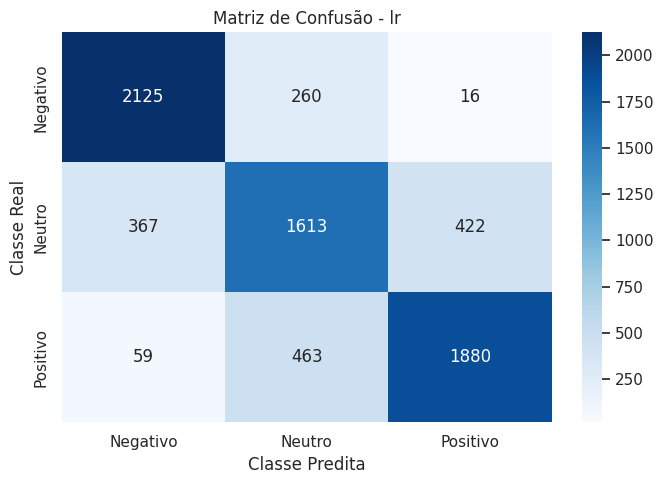

In [111]:
resultado_lr, cm_lr = desempenho_modelo(y_test, pred_test_lr, 'lr')

,Modelo,Accuracy,Precision,Recall,F1-Score
0,svm,0.781957,0.7794,0.781973,0.779882



Relatório detalhado - svm:
              precision    recall  f1-score   support

    Negativo       0.82      0.90      0.86      2401
      Neutro       0.70      0.66      0.68      2402
    Positivo       0.81      0.79      0.80      2402

    accuracy                           0.78      7205
   macro avg       0.78      0.78      0.78      7205
weighted avg       0.78      0.78      0.78      7205



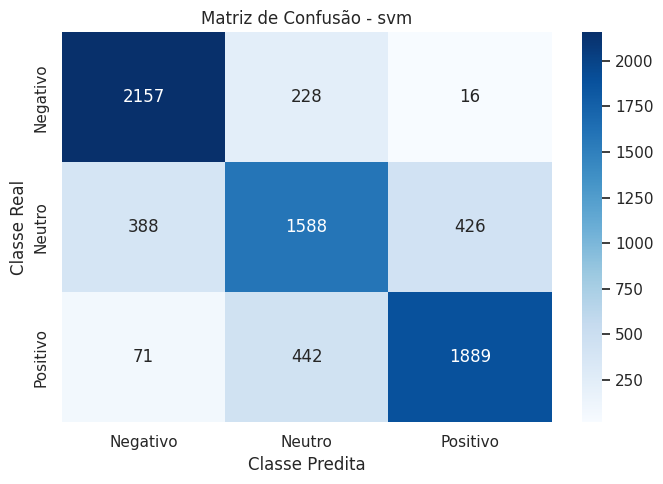

In [112]:
resultado_svm, cm_svm = desempenho_modelo(y_test, pred_test_svm, 'svm')

# 3. Modelo Especializado de Deep Learning (Fine-Tuning BERTimbau)

## 3.1 Bibliotecas

In [113]:
!pip install -q accelerate torch

In [114]:
import torch
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModel,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

device = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_NAME = "neuralmind/bert-base-portuguese-cased"
print(f"Using device: {device}")

Using device: cuda


## 3.2 Tokenizar os textos

In [115]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

In [116]:
# Hugging Face Datasets
train_ds = Dataset.from_dict({'text': X_train.tolist(), 'label': y_train.tolist()})
val_ds = Dataset.from_dict({'text': X_val.tolist(), 'label': y_val.tolist()})
test_ds = Dataset.from_dict({'text': X_test.tolist(), 'label': y_test.tolist()})

In [117]:
print(train_ds)
print(val_ds)
print(test_ds)

Dataset({
    features: ['text', 'label'],
    num_rows: 33621
})
Dataset({
    features: ['text', 'label'],
    num_rows: 7204
})
Dataset({
    features: ['text', 'label'],
    num_rows: 7205
})


In [118]:
# Função em que vai atuar o tokenizador
def tokenize_fn(batch):
  return tokenizer(batch['text'], max_length = 256, truncation=True)

In [119]:
# Tokenizando os textos para entrar no BERT
train_tok = train_ds.map(tokenize_fn, batched = True, remove_columns = ["text"])
val_tok = val_ds.map(tokenize_fn, batched = True, remove_columns = ["text"])
test_tok = test_ds.map(tokenize_fn, batched = True, remove_columns = ["text"])

Map:   0%|          | 0/33621 [00:00<?, ? examples/s]

Map:   0%|          | 0/7204 [00:00<?, ? examples/s]

Map:   0%|          | 0/7205 [00:00<?, ? examples/s]

In [120]:
# Ajustar os tamanhos das sequências em cada batch
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
data_collator

DataCollatorWithPadding(tokenizer=BertTokenizer(name_or_path='neuralmind/bert-base-portuguese-cased', vocab_size=29794, model_max_length=1000000000000000019884624838656, padding_side='right', truncation_side='right', special_tokens={'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'}, added_tokens_decoder={
	0: AddedToken("[PAD]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	100: AddedToken("[UNK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	101: AddedToken("[CLS]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	102: AddedToken("[SEP]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	103: AddedToken("[MASK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
}), padding=True, max_length=None, pad_to_multiple_of=None, return_tensors='pt')

## 3.3 Fine-Tuning do BERTimbau

In [121]:
# "Cabeça de classificação" pra 3 classes
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels = 3)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

In [122]:
def compute_metrics(eval_pred):
  logits, labels = eval_pred
  preds = np.argmax(logits, axis=-1)

  return {
        "accuracy": accuracy_score(labels, preds),
        "f1_macro": f1_score(labels, preds, average="macro"),
        "precision_macro": precision_score(labels, preds, average="macro"),
        "recall_macro": recall_score(labels, preds, average="macro"),
    }

In [123]:
# Parâmetros do treinamento
training_args = TrainingArguments(
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    fp16=torch.cuda.is_available(),
    seed=RANDOM_STATE,
    report_to="none"
)

In [124]:
# Instanciação do Bert para Fine-Tuning
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tok,
    eval_dataset=val_tok,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

In [125]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,Precision Macro,Recall Macro
1,0.449150,0.427419,0.835092,0.832746,0.833002,0.835077
2,0.383947,0.437846,0.837868,0.837235,0.837406,0.837856
3,0.326381,0.462698,0.832732,0.832031,0.831580,0.832721


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=3153, training_loss=0.4000653388800411, metrics={'train_runtime': 475.3509, 'train_samples_per_second': 212.186, 'train_steps_per_second': 6.633, 'total_flos': 8707627044841662.0, 'train_loss': 0.4000653388800411, 'epoch': 3.0})

,Modelo,Accuracy,Precision,Recall,F1-Score
0,BERTimbau_FineTuned,0.828175,0.827247,0.828188,0.827366



Relatório detalhado - BERTimbau_FineTuned:
              precision    recall  f1-score   support

    Negativo       0.87      0.92      0.90      2401
      Neutro       0.75      0.74      0.75      2402
    Positivo       0.85      0.82      0.84      2402

    accuracy                           0.83      7205
   macro avg       0.83      0.83      0.83      7205
weighted avg       0.83      0.83      0.83      7205



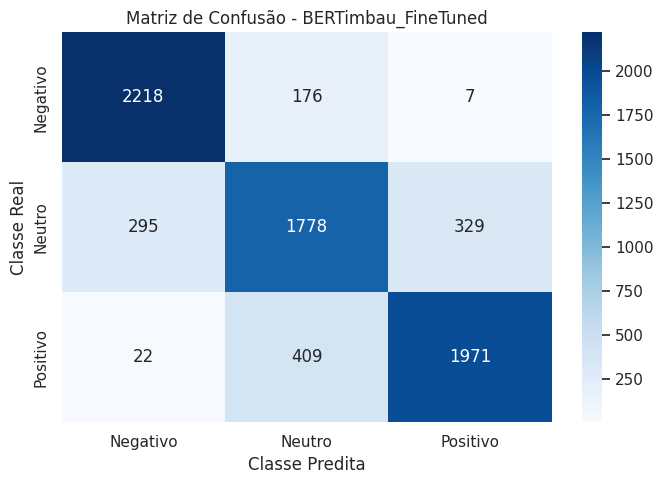

In [126]:
# Avaliação no conjunto de teste somente com o BERTimbau
preds_output = trainer.predict(test_tok)
pred_test_bert = np.argmax(preds_output.predictions, axis=-1)

resultado_bert, cm_bert = desempenho_modelo(y_test, pred_test_bert, "BERTimbau_FineTuned")

## 3.4 Embedding com BERTimbau

In [127]:
base_model = model.bert # largando a cabeça de classificação
base_model.eval()

@torch.no_grad() # não vai ter mudança nos pesos
def extrair_embeddings(texto, batch_size = 64, max_length = 256):
  embeddings = []

  for i in range(0, len(texto), batch_size):
    batch = texto[i:i + batch_size]
    enc = tokenizer ( # Passar pra tensores
        batch,
        padding=True,
        truncation=True,
        max_length=max_length,
        return_tensors='pt').to(device)

    out = base_model(**enc)

    # Mean Pooling ponderado pela attention-mask (Média dos embeddings dos tokens)
    mask = enc["attention_mask"].unsqueeze(-1).expand(out.last_hidden_state.size()).float()
    sum_emb = torch.sum(out.last_hidden_state * mask, dim=1)
    sum_mask = torch.clamp(mask.sum(dim=1), min=1e-9)
    mean_emb = (sum_emb / sum_mask).cpu().numpy()
    embeddings.append(mean_emb)

  return np.vstack(embeddings)

In [128]:
print("Extraindo embeddings de treino e teste...")
X_train_emb = extrair_embeddings(X_train.tolist())
X_test_emb  = extrair_embeddings(X_test.tolist())

Extraindo embeddings de treino e teste...


## 3.5 Treinamentos de Modelos de Machine Learning



### 3.5.1 Regressão Logística

In [129]:
from sklearn.preprocessing import StandardScaler

In [130]:
param_grid_emb = {'clf__C': [0.01, 0.1, 1.0]}

In [131]:
print("Otimizando Regressão Logística nos embeddings via GridSearchCV (cv=3)...")
pipe_lr_emb = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])

grid_lr_emb = GridSearchCV(
    pipe_lr_emb,
    param_grid_emb,
    cv=3,
    scoring='f1_macro',
    n_jobs=-1
)
grid_lr_emb.fit(X_train_emb, y_train)
best_lr_emb = grid_lr_emb.best_estimator_

print(f"-> Melhor 'C' para Regressão Logística (Embeddings): {grid_lr_emb.best_params_['clf__C']}")

Otimizando Regressão Logística nos embeddings via GridSearchCV (cv=3)...
-> Melhor 'C' para Regressão Logística (Embeddings): 0.01


In [132]:
pred_test_lr_emb  = best_lr_emb.predict(X_test_emb)

,Modelo,Accuracy,Precision,Recall,F1-Score
0,BERTimbau_Embeddings_LR,0.819709,0.818954,0.819719,0.8193



Relatório detalhado - BERTimbau_Embeddings_LR:
              precision    recall  f1-score   support

    Negativo       0.88      0.90      0.89      2401
      Neutro       0.74      0.73      0.73      2402
    Positivo       0.84      0.83      0.83      2402

    accuracy                           0.82      7205
   macro avg       0.82      0.82      0.82      7205
weighted avg       0.82      0.82      0.82      7205



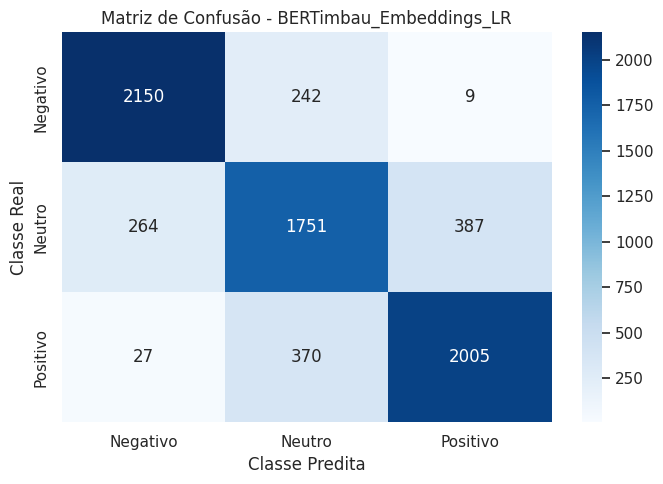

In [133]:
resultado_lr_emb, cm_lr_emb   = desempenho_modelo(y_test, pred_test_lr_emb,  "BERTimbau_Embeddings_LR")

### 3.5.2 SVM

In [134]:
print("\nOtimizando LinearSVC nos embeddings via GridSearchCV (cv=3)...")
pipe_svm_emb = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LinearSVC(max_iter=2000, random_state=RANDOM_STATE))
])

grid_svm_emb = GridSearchCV(
    pipe_svm_emb,
    param_grid_emb,
    cv=3,
    scoring='f1_macro',
    n_jobs=-1
)
grid_svm_emb.fit(X_train_emb, y_train)
best_svm_emb = grid_svm_emb.best_estimator_

print(f"-> Melhor 'C' para LinearSVC (Embeddings): {grid_svm_emb.best_params_['clf__C']}")


Otimizando LinearSVC nos embeddings via GridSearchCV (cv=3)...
-> Melhor 'C' para LinearSVC (Embeddings): 0.01


In [135]:
pred_test_svm_emb = best_svm_emb.predict(X_test_emb)

,Modelo,Accuracy,Precision,Recall,F1-Score
0,BERTimbau_Embeddings_SVM,0.824844,0.823788,0.824855,0.82423



Relatório detalhado - BERTimbau_Embeddings_SVM:
              precision    recall  f1-score   support

    Negativo       0.88      0.90      0.89      2401
      Neutro       0.75      0.73      0.74      2402
    Positivo       0.84      0.84      0.84      2402

    accuracy                           0.82      7205
   macro avg       0.82      0.82      0.82      7205
weighted avg       0.82      0.82      0.82      7205



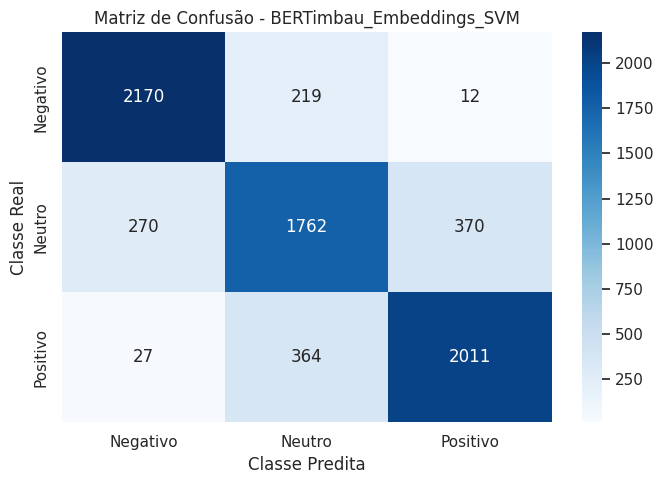

In [136]:
resultado_svm_emb, cm_svm_emb = desempenho_modelo(y_test, pred_test_svm_emb, "BERTimbau_Embeddings_SVM")

# 4.  Avaliação Comparativa e Análise Qualitativa de Casos Isolados